# Downsampling

1. Overlap with the 100% dataset: Jaccard index bar plot (reference is each caller's own 100% calls)
2. ChIP-seq signal at loading sites vs downsampling proportion (line plot)

In [1]:
import sys
sys.path.append('..')
import os
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bioframe as bf
import yaml

from utils.plotting import genomic_labels
from func_iou import generate_positions, match_by_iou, unique_pairs
from func_pileup import generate_bed_3
from func_analysis import extract_chipseq_values

In [2]:
cf = """
samples:

  DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_50kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped.hic"
    q_val: "0.15"
    q_val_white: "0.15"

  DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75:
    file: "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.75_inter.hic"
    q_val: "0.15"
    q_val_white: "0.15"

  DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5:
    file: "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.5_inter.hic"
    q_val: "0.15"
    q_val_white: "0.15"

  DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25:
    file: "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.25_inter.hic"
    q_val: "0.15"
    q_val_white: "0.15"

  DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1:
    file: "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.1_inter.hic"
    q_val: "0.15"
    q_val_white: "0.15"
"""

config = yaml.safe_load(cf)
samples = config["samples"]

In [3]:
analysis_dir = "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_v2.0.3"

names_abrev = ['100%', '75%', '50%', '25%', '10%']

genome = "mm10"
chromsizes = bf.fetch_chromsizes(db=genome, as_bed=True)
common_chroms = chromsizes["chrom"].tolist()
common_chroms.remove('chrY')
common_chroms.remove('chrM')

In [4]:
resolution = 50000

fun_bedpes = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_50kb/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1/FUN-pred_50000_1.3.bedpe",
]

fun_tabs = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_50kb/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1/FUN-pred_50000_1.3.tab",
]

fontankas = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_50kb.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1.50000.predicted.fountains.thresholded.tsv",
]

In [5]:
output_name = "v2.0.3"

positions = []
tables = []
names = []

for i, sample_key in enumerate(samples):
    attributes = samples[sample_key]

    hic_name = os.path.basename(attributes["file"]).split(".hic")[0]
    q_val_white_str = f"q_val_{attributes['q_val']}-{attributes['q_val_white']}"

    # ===================== MIA-JET =====================
    folder = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution)}"
    prefix = f"{hic_name}_chr_combined_"
    suffix = f"_{genomic_labels(resolution)}_summary_table.csv"
    fname = next(f for f in os.listdir(folder) if f.startswith(prefix) and f.endswith(suffix) and q_val_white_str in f)
    result_type = fname[len(prefix):-len(suffix)]
    f_s = os.path.join(folder, fname)
    f_e = os.path.join(folder, f"{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv")

    miajet_positions = pd.read_csv(f_e, comment="#")
    miajet_table = pd.read_csv(f_s, comment="#")

    # ===================== FUN =====================
    fun_bedpe = pd.read_csv(fun_bedpes[i], sep="\t")
    fun_table = pd.read_csv(fun_tabs[i], sep="\t")

    # ===================== FONTANKA =====================
    fontanka_table = pd.read_csv(fontankas[i], sep="\t", index_col=0)
    fontanka_table.dropna(inplace=True, how="any")
    fontanka_table.reset_index(inplace=True, drop=True)

    # ---- restrict every method to the common chromosomes ----
    miajet_table = miajet_table[miajet_table["chrom"].isin(common_chroms)]
    fun_table = fun_table[fun_table["chrom"].isin(common_chroms)]
    fontanka_table = fontanka_table[fontanka_table["chrom"].isin(common_chroms)]

    # ---- FUN -> positions ----
    fun_bedpe["extrusion_x"] = (fun_bedpe["y1"] + fun_bedpe["y2"]) / 2
    fun_bedpe["extrusion_y"] = (fun_bedpe["x1"] + fun_bedpe["x2"]) / 2
    assert np.all(fun_bedpe["extrusion_x"] >= fun_bedpe["extrusion_y"])

    fun_table["root"] = (fun_table["start"] + fun_table["end"]) / 2
    fun_table["unique_id"] = fun_table.index

    fun_minimal = fun_bedpe.copy()
    fun_minimal["root"] = fun_table["root"]
    fun_minimal["unique_id"] = fun_minimal.index
    fun_minimal["chrom"] = fun_table["chrom"]
    fun_minimal = fun_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

    fun_positions = generate_positions(fun_minimal, resolution)
    fun_positions["unique_id"] = fun_positions["unique_id"].astype(int)

    # ---- FONTANKA -> positions ----
    fontanka_table = fontanka_table.reset_index(drop=True)
    fontanka_table["root"] = (fontanka_table["end"] + fontanka_table["start"]) / 2
    fontanka_table["unique_id"] = fontanka_table.index
    fontanka_table["extrusion_x"] = fontanka_table["window_end"]
    fontanka_table["extrusion_y"] = fontanka_table["window_start"]
    assert np.all(fontanka_table["extrusion_x"] >= fontanka_table["extrusion_y"])

    fontanka_minimal = fontanka_table.copy()
    fontanka_minimal = fontanka_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

    fontanka_positions = generate_positions(fontanka_minimal, resolution)
    fontanka_positions["unique_id"] = fontanka_positions["unique_id"].astype(int)

    # ===================== append one entry per method for this sample =====================
    positions.extend([miajet_positions, fun_positions, fontanka_positions])
    tables.extend([miajet_table, fun_table, fontanka_table])
    names.extend([
        f"{names_abrev[i]} MIA-Jet",
        f"{names_abrev[i]} Fun",
        f"{names_abrev[i]} Fontanka",
    ])

position_dict = dict(zip(names, positions))
table_dict = dict(zip(names, tables))

## Overlap with the 100% dataset

In [6]:
buffer_radius = 3 * resolution  # 3 bins
iou_threshold = 0  # ANY overlap

unique_identifiers = []
name_pairs = []

for n1, n2 in itertools.combinations(names, 2):
    print(f"Comparing {n1} and {n2}...")

    identifiers = []
    for chrom in common_chroms:
        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")
        identifiers += pairs # extend the list

    unique_identifiers.append(identifiers)
    name_pairs.append((n1, n2))

Comparing 100% MIA-Jet and 100% Fun...


Comparing 100% MIA-Jet and 100% Fontanka...


Comparing 100% MIA-Jet and 75% MIA-Jet...


Comparing 100% MIA-Jet and 75% Fun...


Comparing 100% MIA-Jet and 75% Fontanka...


Comparing 100% MIA-Jet and 50% MIA-Jet...


... (86 outputs left out)

Comparing 25% Fontanka and 10% Fun...


Comparing 25% Fontanka and 10% Fontanka...
Comparing 10% MIA-Jet and 10% Fun...


Comparing 10% MIA-Jet and 10% Fontanka...


Comparing 10% Fun and 10% Fontanka...


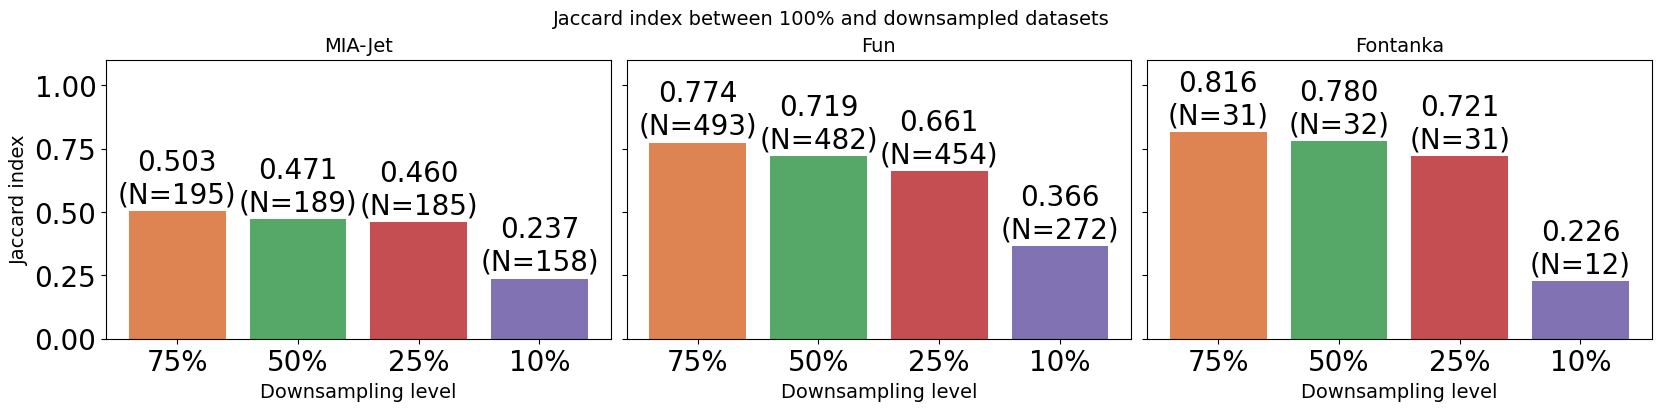

In [7]:
ref_label = "100%"
methods = ["MIA-Jet", "Fun", "Fontanka"]

# downsample levels to compare against each method's own 100%
levels = [
    ("75%", "75%"),
    ("50%", "50%"),
    ("25%", "25%"),
    ("10%", "10%"),
]

palette = {
    "75%":  "#DD8452",
    "50%":  "#55A868",
    "25%":  "#C44E52",
    "10%":  "#8172B3",
}

# symmetric lookup of pairwise overlap counts from the IOU matching above
overlap_lookup = {}
for (a, b), ids in zip(name_pairs, unique_identifiers):
    overlap_lookup[(a, b)] = len(ids)
    overlap_lookup[(b, a)] = len(ids)

# precompute jaccard / overlap per method (so we can share a y-axis sensibly)
data = {}  # method -> (labels, jaccards, overlaps)
for method in methods:
    reference = f"{ref_label} {method}"          # this method's 100%
    labels, jaccards, overlaps = [], [], []
    for level_key, level_label in levels:
        ds_name = f"{level_key} {method}"        # this method at this level
        total_A = len(table_dict[reference])
        total_B = len(table_dict[ds_name])
        inter   = overlap_lookup[(reference, ds_name)]
        jacc    = inter / (total_A + total_B - inter)

        labels.append(level_label)
        jaccards.append(jacc)
        overlaps.append(inter)
    data[method] = (labels, jaccards, overlaps)

fig, axes = plt.subplots(1, len(methods), figsize=(5.5 * len(methods), 4),
                         layout="constrained", sharey=True)

for ax, method in zip(axes, methods):
    labels, jaccards, overlaps = data[method]
    bars = ax.bar(labels, jaccards, color=[palette[l] for l in labels])

    ax.set_xlabel("Downsampling level", fontsize=14)
    ax.set_title(method, fontsize=14)
    ax.tick_params(axis='x', labelsize=20)
    ax.tick_params(axis='y', labelsize=20)

    for bar, jacc, ov in zip(bars, jaccards, overlaps):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{jacc:.3f}\n(N={ov})", ha="center", va="bottom", fontsize=20)

axes[0].set_ylim(0, 1.1)                        # shared across panels
axes[0].set_ylabel("Jaccard index", fontsize=14)
fig.suptitle("Jaccard index between 100% and downsampled datasets", fontsize=14)

plt.savefig(os.path.join(analysis_dir, f"downsampling_bar_{resolution}.png"), dpi=300)
plt.show()

## ChIP-seq signal at loading sites

In [8]:
# Should be the resolution of the miajet program
# This should be standardized across all methods
# This parameter is used to define the sampling frequency of the jet lines
resolution = 50000 # 50Kb resolution

hic_files = [
    "/nfs/turbo/umms-minjilab/downloaded_data/DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.75_inter.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.5_inter.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.25_inter.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/downsampled_files/merged.multires_0.1_inter.hic",
]

data_names = [
    os.path.basename(x).split(".hic")[0] for x in hic_files
]

fun_bedpes = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_50kb/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25/FUN-pred_50000_1.3.bedpe",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1/FUN-pred_50000_1.3.bedpe",
]

fun_tabs = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_50kb/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25/FUN-pred_50000_1.3.tab",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FUN_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1/FUN-pred_50000_1.3.tab",
]

fontankas = [
    f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_{resolution // 1e3:.0f}kb.{resolution}.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.75.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.5.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.25.50000.predicted.fountains.thresholded.tsv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/other_methods/FONTANKA_ws-small_DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped_0.1.50000.predicted.fountains.thresholded.tsv",
]

# MIA-JET
output_name = "v2.0.3"
result_type = "q_val_0.15-0.15" # 50 bkb (OK)
resolution_miajet = resolution
miajet_summarys = [
    f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{data_names[i]}_chr_combined_{genomic_labels(resolution_miajet)}/{data_names[i]}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_summary_table.csv"
    for i in range(len(data_names))
]
miajet_expandeds = [
    f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{data_names[i]}_chr_combined_{genomic_labels(resolution_miajet)}/{data_names[i]}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_expanded_table.csv"
    for i in range(len(data_names))
]
result_type += " sum_consistency"  # MIA-Jet ranking column; only used in the saved figure name

# AUXILIAR DATA (ChIP-seq)
# remapped the following using liftover_bedgraph.ipynb
chip_files = [
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_input-R1_chipseq_Guo-2022_GSM5963432_mm10.bedGraph",
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_H3K27ac-R1_chipseq_Guo-2022_GSM5963434_mm10.bedGraph",
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_RAD21-R1_chipseq_Guo-2022_GSM5963436_mm10.bedGraph",
    "/nfs/turbo/umms-minjilab/downloaded_data/dp_thymocytes_CTCF_chipseq_Guo-2022_GSM5963438_mm10.bedGraph",
    "/nfs/turbo/umms-minjilab/processing/results/SRR931714/dp_thymocytes_NIPBL_SRR931714_miseq.q30.nr.sorted.mm10.bedgraph",
]

chip_names_abrev = ["Input", "H3K27ac", "RAD21", "CTCF", "NIPBL"]

f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/mm10/mm10.chrom.sizes"

# ChIP-seq parameters
stat = "max"
window_plus_minus = int(50e3) # 50 kb

# Common parameters
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

In [9]:
# x-axis order matches data_names (1.0, 0.75, 0.5, 0.25, 0.1)
downsample_proportions = [1.0, 0.75, 0.5, 0.25, 0.1]
caller_labels = ["MIA-Jet", "Fun", "Fontanka"]   # order matches `tables` / `positions` built in the loop

# collected_chipseq[chip_abbrev][caller] is a list with one entry per dataset,
# each entry being the cleaned + log-transformed ChIP-seq value array
collected_chipseq = {
    chip: {caller: [None] * len(hic_files) for caller in caller_labels}
    for chip in chip_names_abrev
}

for i in range(len(hic_files)):
    print(f"Processing {data_names[i]}...")

    # Load it in
    fun_bedpe = pd.read_csv(fun_bedpes[i], sep="\t")
    fun_table = pd.read_csv(fun_tabs[i], sep="\t")

    fontanka_table = pd.read_csv(fontankas[i], sep="\t", index_col=0)
    fontanka_table.dropna(inplace=True, how="any")
    fontanka_table.reset_index(inplace=True, drop=True)

    miajet_positions = pd.read_csv(miajet_expandeds[i], comment="#")
    miajet_table = pd.read_csv(miajet_summarys[i], comment="#")

    # For a fair comparison, only consider the common chromosomes
    miajet_table = miajet_table[miajet_table["chrom"].isin(common_chroms)]
    fun_table = fun_table[fun_table["chrom"].isin(common_chroms)]
    fontanka_table = fontanka_table[fontanka_table["chrom"].isin(common_chroms)]

    # midpoint
    fun_bedpe["extrusion_x"] = (fun_bedpe["y1"] + fun_bedpe["y2"]) / 2
    fun_bedpe["extrusion_y"] = (fun_bedpe["x1"] + fun_bedpe["x2"]) / 2

    # guarantees that the extrusion point is in the upper diagonal
    # doesn't matter except for convention but should be standardized for all points
    assert np.all(fun_bedpe["extrusion_x"] >= fun_bedpe["extrusion_y"])

    # the main table hosts the "start" and "end" positions, which is the main diagonal start and end
    # to get a single point for the jet, we can use the midpoint of the start and end positions
    fun_table["root"] = (fun_table["start"] + fun_table["end"]) / 2
    # Note that "root" position should technically be "root_x" and "root_y" but since
    # this is a point on the main diagonal, they are the same and we can just use one value

    # Lets add a unique identifier now
    fun_table["unique_id"] = fun_table.index

    # Lets combine them
    fun_minimal = fun_bedpe.copy()
    fun_minimal["root"] = fun_table["root"]
    fun_minimal["unique_id"] = fun_minimal.index
    fun_minimal["chrom"] = fun_table["chrom"]
    fun_minimal = fun_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

    fun_positions = generate_positions(fun_minimal, resolution)
    fun_positions["unique_id"] = fun_positions["unique_id"].astype(int)

    fontanka_table = fontanka_table.reset_index(drop=True)
    fontanka_table["root"] = (fontanka_table["end"] + fontanka_table["start"]) / 2
    fontanka_table["unique_id"] = fontanka_table.index
    fontanka_table["extrusion_x"] = fontanka_table["window_end"]
    fontanka_table["extrusion_y"] = fontanka_table["window_start"]

    # guarantees that the extrusion point is in the upper diagonal
    # doesn't matter except for convention but should be standardized for all points
    assert np.all(fontanka_table["extrusion_x"] >= fontanka_table["extrusion_y"])

    fontanka_minimal = fontanka_table.copy()
    fontanka_minimal = fontanka_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

    fontanka_positions = generate_positions(fontanka_minimal, resolution)
    fontanka_positions["unique_id"] = fontanka_positions["unique_id"].astype(int)

    # Expanded
    positions = [
        miajet_positions,
        fun_positions,
        fontanka_positions,
    ]

    # Summary
    tables = [
        miajet_table,
        fun_table,
        fontanka_table,
    ]

    # For ChIP-seq we use the loading site locations
    bed_tables = []
    for s, e in zip(tables, positions):
        bed_tables.append(generate_bed_3(s, e))

    intervals = []
    for t in bed_tables:
        df_interval = t[["unique_id", "chrom"]].copy()
        df_interval["midpoint"] = (t["start"] + t["end"]) / 2
        df_interval["start"] = df_interval["midpoint"] - window_plus_minus
        df_interval["end"] = df_interval["midpoint"] + window_plus_minus

        intervals.append(df_interval.reset_index(drop=True))

    # Takes the longest
    chipseq_values = extract_chipseq_values(chip_files, intervals, f_chrom_sizes, common_chroms, caller_labels, stat=stat)

    # COLLECT DATA
    for c, chip_abbrev in enumerate(chip_names_abrev):
        datum = chipseq_values[c]
        boxplot_data = [list(x.values()) for x in datum]

        clean_data = [np.array(vals)[~np.isnan(vals)] for vals in boxplot_data]
        clean_data = [np.clip(vals, 0, None) for vals in clean_data]   # clip negatives
        clean_data = [np.log10(vals + 1) for vals in clean_data]       # log transform

        for j, caller in enumerate(caller_labels):
            collected_chipseq[chip_abbrev][caller][i] = clean_data[j]

Processing DP-thymocytes_WT_hic_Guo-2022_GSE199059_mm10-remapped...


chr1 is already loaded


chr2 is already loaded


chr3 is already loaded


chr4 is already loaded


chr5 is already loaded


... (900 outputs left out)

chr15 is already loaded


chr19 is already loaded


chrX is already loaded


No jets called for chromosome chr9 by Fontanka
No jets called for chromosome chr10 by Fontanka
No jets called for chromosome chr16 by Fontanka
No jets called for chromosome chr17 by Fontanka
No jets called for chromosome chr18 by Fontanka


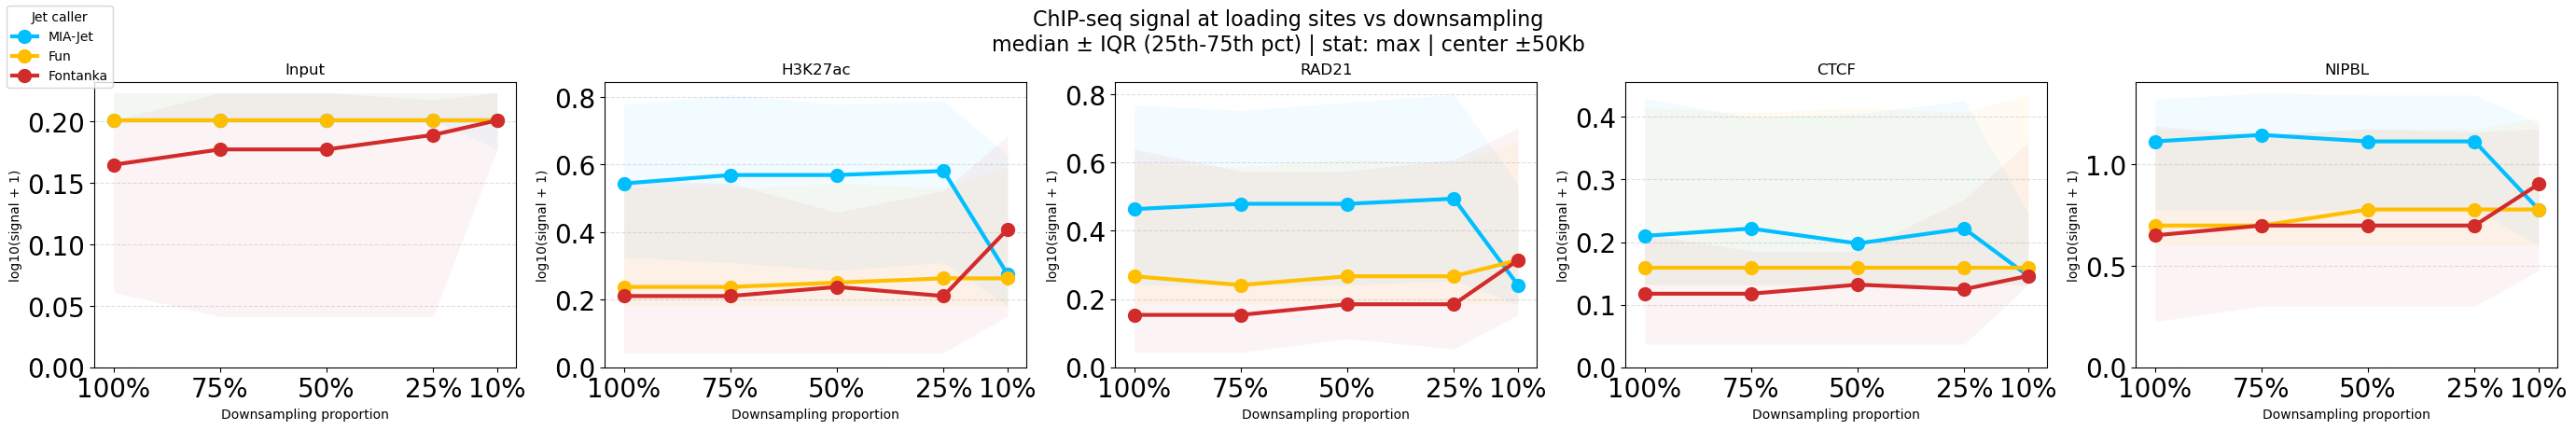

In [10]:
x = np.array(downsample_proportions) * 100        # [75, 50, 25, 10]
dodge = 0                                        # small horizontal offset per caller

palette = {"MIA-Jet": "#00bfff", "Fun": "#ffbf00", "Fontanka": "#d22b2b"}

n_exp = len(chip_names_abrev)
fig, axes = plt.subplots(1, n_exp, figsize=(5.5 * n_exp, 4.5), layout="constrained")
if n_exp == 1:
    axes = [axes]

for k, chip in enumerate(chip_names_abrev):
    ax = axes[k]
    for j, caller in enumerate(caller_labels):
        medians, lowers, uppers = [], [], []
        for d in range(len(downsample_proportions)):
            vals = np.asarray(collected_chipseq[chip][caller][d], dtype=float)
            vals = vals[~np.isnan(vals)]
            if vals.size == 0:
                medians.append(np.nan); lowers.append(np.nan); uppers.append(np.nan)
                continue
            med = np.median(vals)
            p25, p75 = np.percentile(vals, [25, 75])
            medians.append(med)
            lowers.append(p25)              # 25th percentile (lower bound)
            uppers.append(p75)              # 75th percentile (upper bound)

        medians = np.asarray(medians)
        lowers  = np.asarray(lowers)
        uppers  = np.asarray(uppers)

        x_off = x + (j - (len(caller_labels) - 1) / 2) * dodge   # dodge so lines don't overlap

        # median line
        ax.plot(
            x_off, medians,
            marker="o", linewidth=3, markersize=10,
            color=palette[caller], label=caller,
        )
        # shaded IQR contour in the same color
        ax.fill_between(
            x_off, lowers, uppers,
            color=palette[caller], alpha=0.05, linewidth=0, 
        )

    ax.set_title(chip)
    ax.set_xlabel("Downsampling proportion")
    ax.set_ylabel("log10(signal + 1)")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{p:.0f}%" for p in x], fontsize=20)
    ax.tick_params(axis='y', labelsize=20)
    ax.set_ylim(bottom=0)
    ax.invert_xaxis()                       # 75% on the left, 10% on the right
    ax.grid(axis="y", linestyle="--", alpha=0.4)

# single shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", title="Jet caller")

fig.suptitle(
    f"ChIP-seq signal at loading sites vs downsampling\n"
    f"median ± IQR (25th-75th pct) | stat: {stat} | center ±{genomic_labels(window_plus_minus)}",
    fontsize=16,
)

plt.savefig(f"{save_path}/lineplot_chipseq_vs_downsampling_{resolution_miajet}_{result_type}_contours.png", dpi=300)

plt.show()